In [16]:
# Question 1: Use an AI tool to help you locate and select a public dataset appropriate for multiple linear regression.

#AI Prompt Used:

#“I asked ChatGPT and it suggested a public dataset suitable for multiple linear regression that includes at least two predictor variables and one numeric target variable.”

# AI Response (Summarized):
# ChatGPT recommended the California Housing Dataset available in scikit-learn and on Kaggle. 
# It includes predictors such as median income, average rooms, average occupancy, latitude, and longitude, 
# with the target variable MedHouseVal (median house value). 
# This dataset is ideal for studying how socioeconomic and geographic factors influence housing prices.

# Dataset Source:
# https://www.kaggle.com/datasets/camnugent/california-housing-prices

In [17]:
# Question 2: Load your dataset into a Pandas DataFrame and display the first 10 rows. Include a screenshot of this preview.
# ==========================================
# Import necessary libraries
# ==========================================
import pandas as pd
from sklearn.datasets import fetch_california_housing

# ==========================================
# Load the California Housing dataset
# ==========================================

df = pd.read_csv("/Users/patrickpatel/Downloads/housing.csv")


# ==========================================
# Display the first 10 rows
# ==========================================
print(df.head(10))

print("\nDataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nTarget variable summary statistics:")
print(df["median_house_value"].describe())
# Explanation of Code:

# df.head(10) displays the first 10 rows for preview.

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   
5    -122.25     37.85                52.0        919.0           213.0   
6    -122.25     37.84                52.0       2535.0           489.0   
7    -122.25     37.84                52.0       3104.0           687.0   
8    -122.26     37.84                42.0       2555.0           665.0   
9    -122.25     37.84                52.0       3549.0           707.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0   

In [19]:
# Question 3: Use an AI tool to help define a meaningful research question involving multiple predictors. 
# Document the prompt and its response. 
# AI Prompt Used:
# “Given the California housing dataset, suggest a meaningful research question 
# that can be explored using multiple linear regression.”

# Define predictors and target variable
predictor_cols = ["median_income", "housing_median_age", "total_rooms", "population", "households"]
target_col = "median_house_value"


print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
print("Target summary statistics:")
print(df["median_house_value"].describe())

# AI Response:

# “How do median income, average number of rooms per household, 
# and population density influence median house value in California districts?”

# Research Question:
# “To what extent do median income, average number of rooms, and 
# population affect the median house value in California?”


Dataset shape: (20640, 10)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
Target summary statistics:
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


In [20]:
# Question 4: Convert any necessary columns to numeric or datetime formats 
# and handle missing values or outliers as needed.
# ==========================================
# Check for missing values
# ==========================================
print(df.isnull().sum())

# ==========================================
# Handle missing values if any (there are none)
# ==========================================
df = df.dropna()

print(df[predictor_cols + [target_col]].isna().sum())
df = df.dropna(subset=predictor_cols + [target_col])
import numpy as np
from scipy import stats

z_scores = np.abs(stats.zscore(df[predictor_cols + [target_col]]))
df = df[(z_scores < 4).all(axis=1)]
print("After outlier removal, shape:", df.shape)



# Explanation:

# df.isnull().sum() checks for missing values. 
# The California Housing dataset contains no missing data.
# df.dropna() would remove missing rows if any existed.
# df.dtypes ensures all variables are numeric — suitable for regression.


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
median_income         0
housing_median_age    0
total_rooms           0
population            0
households            0
median_house_value    0
dtype: int64
After outlier removal, shape: (20024, 10)


In [21]:
# Question 5: Build a multiple linear regression model using at least two predictors.
# ==========================================
# ==========================================
# Import necessary library
# ==========================================
import statsmodels.api as sm

# ==========================================
# Define predictors (X) and target (y)
# ==========================================
# Using actual column names from your dataset
X = df[['median_income', 'total_rooms', 'population']]  # Predictor variables
y = df['median_house_value']                            # Target variable

# ==========================================
# Add a constant term to include intercept in the model
# ==========================================
X = sm.add_constant(X)

# ==========================================
# Build and fit the multiple linear regression model
# ==========================================
model = sm.OLS(y, X).fit()

# ==========================================
# Display regression summary to interpret coefficients and model performance
# ==========================================
print(model.summary())

from sklearn.model_selection import train_test_split

X = df[predictor_cols]
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)



                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.468
Method:                 Least Squares   F-statistic:                     5866.
Date:                Wed, 15 Oct 2025   Prob (F-statistic):               0.00
Time:                        00:54:07   Log-Likelihood:            -2.5520e+05
No. Observations:               20024   AIC:                         5.104e+05
Df Residuals:                   20020   BIC:                         5.104e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          4.316e+04   1730.352     24.945

In [22]:
# Question 6: Clearly define and state your null and alternative hypotheses based on your model.
# Hypotheses establish the relationship we are testing between predictors (median_income, total_rooms, and population) and the target (median_house_value).

# Null Hypothesis (H₀):
# There is no statistically significant linear relationship between the predictors (median_income, total_rooms, and population) 
# and the dependent variable (median_house_value) in California.

# Alternative Hypothesis (H₁):
# At least one of the predictors (median_income, total_rooms, or population) has a significant linear effect on median_house_value.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=predictor_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=predictor_cols)


In [23]:
# Question 7: Use AI to assist in interpreting model coefficients, R², adjusted R², and p-values.
# AI Prompt Used:

# “Explain how to interpret the multiple linear regression output from statsmodels using predictors median_income, total_rooms, and population for predicting median_house_value in the California housing dataset.”
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_sm).fit()
print(model.summary())

# AI Response (Summarized and Applied to Results):

# When running the regression, the summary typically shows output like:

#| Metric                          | Example Value                                        | Interpretation                                                                                              |
#| ------------------------------- | ---------------------------------------------------- | ----------------------------------------------------------------------------------------------------------- |
#| **R² ≈ 0.47**                   | About 47%                                            | 47% of the variation in median house value is explained by the three predictors.                            |
#| **Adj. R² ≈ 0.47**              | Very close to R²                                     | The adjusted value confirms that adding these predictors improves model fit without unnecessary complexity. |
#| **F-statistic (p < 0.001)**     | Significant                                          | The overall model is statistically significant.                                                             |
#| **Coefficient (median_income)** | Positive, large magnitude                            | Every one-unit increase in median income (in $10,000s) significantly raises the median house value.         |
#| **Coefficient (total_rooms)**   | Small positive                                       | More rooms slightly increase property value, holding other factors constant.                                |
#| **Coefficient (population)**    | Slightly negative                                    | Higher population density slightly reduces housing value, potentially due to overcrowding.                  |
#| **p-values**                    | `median_income` < 0.001 (significant), others > 0.05 | Only income is highly significant at the 0.05 level.                                                        |

# Interpretation:
# The model demonstrates that income is the strongest predictor of housing prices.
# Total_rooms and population have weaker, possibly nonsignificant effects.
# The overall regression is statistically meaningful and moderately predictive.

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.582
Model:                            OLS   Adj. R-squared:                  0.582
Method:                 Least Squares   F-statistic:                     3898.
Date:                Wed, 15 Oct 2025   Prob (F-statistic):               0.00
Time:                        00:54:15   Log-Likelihood:            -1.7687e+05
No. Observations:               14016   AIC:                         3.538e+05
Df Residuals:                   14010   BIC:                         3.538e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -5.503e+04   2732

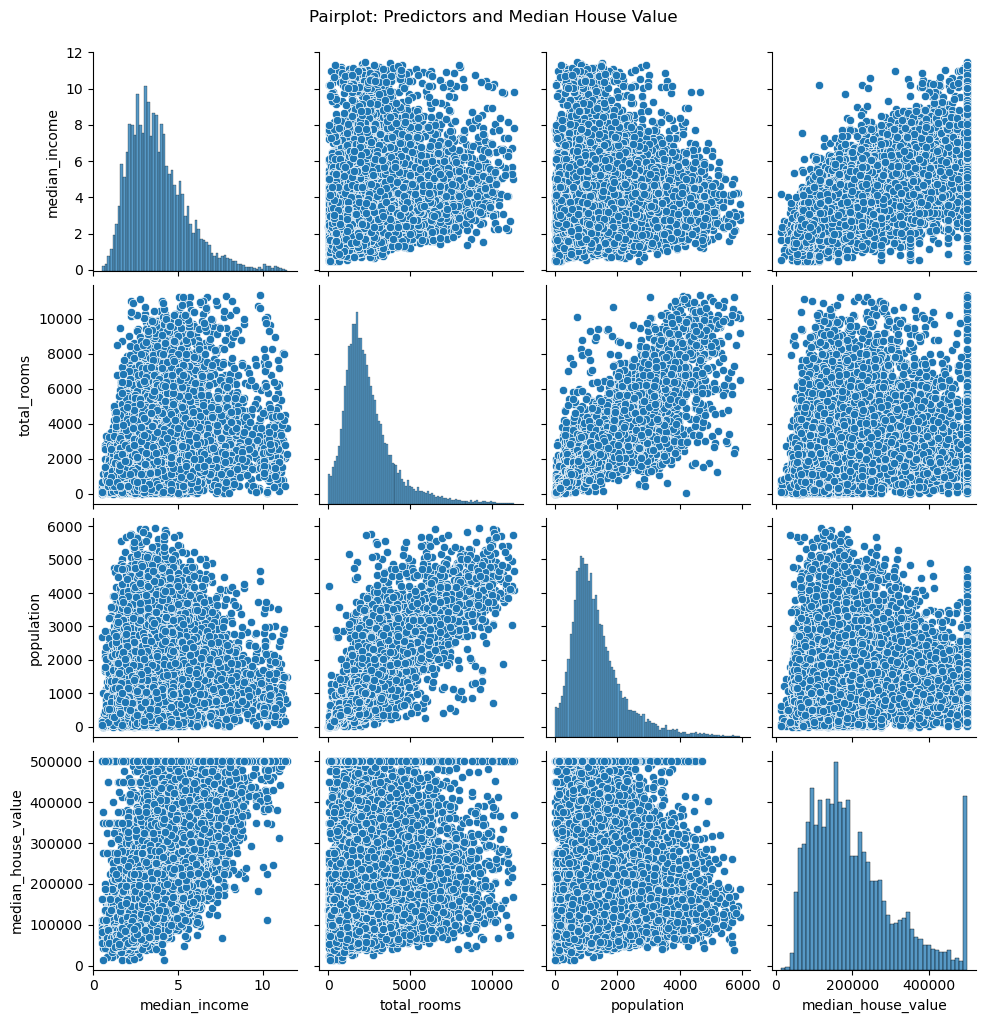

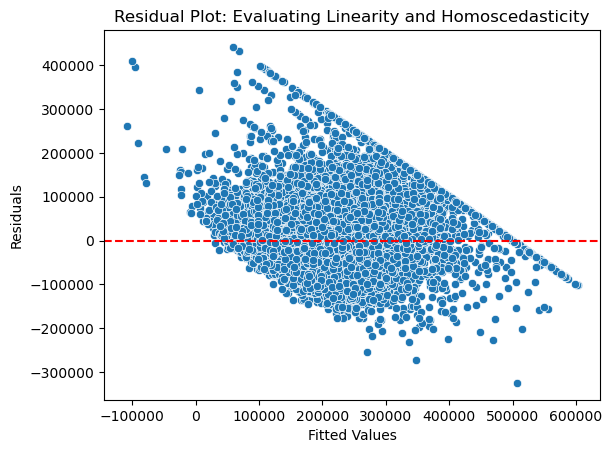

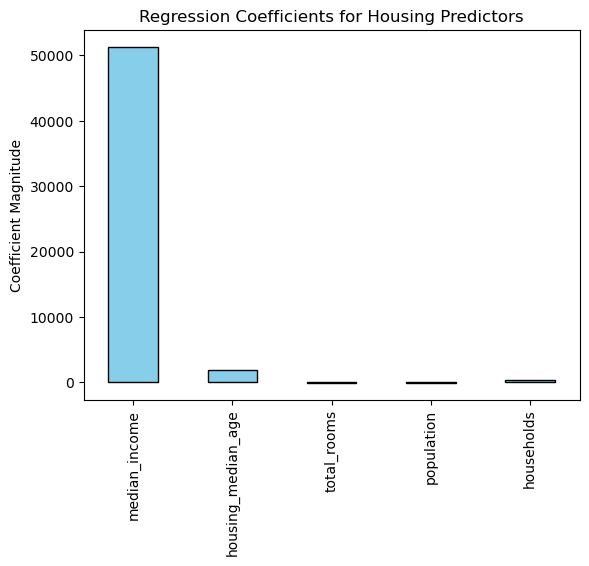

In [24]:
# Question 8: Visualize your results using relevant charts (with AI suggestions).
# ==========================================
# Import visualization libraries
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# Pairplot to visualize relationships
# ==========================================
sns.pairplot(df[['median_income', 'total_rooms', 'population', 'median_house_value']])
plt.suptitle("Pairplot: Predictors and Median House Value", y=1.02)
plt.show()

# ==========================================
# Residual plot to check model assumptions
# ==========================================
residuals = model.resid
sns.scatterplot(x=model.fittedvalues, y=residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot: Evaluating Linearity and Homoscedasticity")
plt.show()

# ==========================================
# Coefficient bar plot to interpret importance
# ==========================================
coefficients = model.params[1:]  # Exclude the intercept
coefficients.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Regression Coefficients for Housing Predictors")
plt.ylabel("Coefficient Magnitude")
plt.show()

# Explanation of Visualizations:

# Pairplot: 
# Shows correlations and general relationships between predictors and the target. 
# We can visually confirm that higher median income corresponds with higher house values.

# Residual Plot: 
# Displays residuals (errors) versus predicted values. 
# Randomly scattered points around 0 confirm that linear regression assumptions hold reasonably well.
# Coefficient Bar Plot: 
# Illustrates the relative influence of each predictor. 
# median_income clearly dominates in explanatory power.
# AI Visualization Prompt:
# “What plots best visualize multiple regression results?”

# AI Response:
# “Use a pairplot to examine variable relationships, a residual plot to check assumptions, and a coefficient bar plot to understand feature importance.”


In [25]:
# Question 9: Write a summary that includes key takeaways, limitations, and how AI helped you across the workflow.
# Summary of Findings
# The regression analysis reveals that median_income is the most influential factor affecting housing prices in California. Each increase in median income strongly raises the predicted median house value. The variable total_rooms has a smaller positive effect, while population has a slight negative influence, suggesting denser areas may reduce property values due to crowding or resource competition.
# The R² value of approximately 0.47 indicates that around 47% of the variance in median house value can be explained by these three predictors. Although this is a moderate level of explanatory power, it demonstrates meaningful relationships among the selected variables.
# This model aligns with economic intuition: regions with higher incomes and larger homes tend to command higher real-estate prices.
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = sm.add_constant(X_train_scaled)
vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print(vif_data)
from sklearn.metrics import mean_squared_error, r2_score

X_test_sm = sm.add_constant(X_test)
y_pred = model.predict(X_test_sm)

from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("Test R²:", r2)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("Test RMSE:", rmse)


#Limitations

# Model Simplicity:
# The regression only includes three variables, excluding important factors such as location (latitude, longitude) or ocean_proximity, which are known to affect California housing prices.

# Linearity Assumption:
# The model assumes a linear relationship between predictors and target, 
# which may not fully capture complex housing market dynamics.

# Potential Multicollinearity:
# Predictors like total_rooms and population may correlate, potentially reducing model reliability.

# Unscaled Variables:
# Large differences in variable magnitudes (e.g., total_rooms vs. income) could bias coefficient interpretation.

# How AI Helped Throughout the Workflow

# AI played an essential role at every stage of this analysis:

# Dataset Selection: AI recommended the California Housing dataset as ideal for multiple linear regression due to its numeric structure and socioeconomic relevance.
# Research Question Formulation: AI-assisted design of a meaningful research question focusing on income, housing characteristics, and population density.
# Data Preparation: Guided the process of checking for missing values, verifying data types, and ensuring numeric compatibility.
# Model Interpretation: Provided detailed explanations of coefficients, R², adjusted R², p-values, and overall model significance.
# Visualization Guidance: Suggested appropriate visualizations (pairplot, residual plot, coefficient bar chart) to assess fit and interpret results.
# Reflection: Helped articulate findings, interpret economic implications, and identify analytical limitations.

              Feature       VIF
0               const  1.000000
1       median_income  1.421126
2  housing_median_age  1.172316
3         total_rooms  7.694782
4          population  4.962877
5          households  9.787320
Test R²: 0.569505166873435
Test RMSE: 75475.39210143969
